# Taller 11: Máquinas de Soporte Vectorial — clasificación de dígitos



## 1. Librerías y datos

In [1]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
SEMILLA = 42
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 20)
print("scikit-learn", sklearn.__version__)

digits = load_digits()
X, y = digits.data, digits.target
print("X:", X.shape, "| clases:", np.unique(y), "| píxeles de", X.min(), "a", X.max())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEMILLA, stratify=y)
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=SEMILLA)
print(f"Entrenamiento: {len(X_train)} | Prueba: {len(X_test)} | K-fold = {cv.get_n_splits()}")

scikit-learn 1.6.1
X: (1797, 64) | clases: [0 1 2 3 4 5 6 7 8 9] | píxeles de 0.0 a 16.0
Entrenamiento: 1437 | Prueba: 360 | K-fold = 4


2. Comparación inicial de kernels (parámetros por defecto)
Primero se evalúa cada kernel con sus hiperparámetros por defecto (`C=1`, `gamma='scale'`, `degree=3`). Se reportan el promedio y la desviación estándar de las métricas en los 4 folds.

In [2]:
METRICAS = {"accuracy": "accuracy", "precision": "precision_macro",
            "recall": "recall_macro", "f1": "f1_macro"}

def svm_pipe(**kw):
    return Pipeline([("escala", StandardScaler()), ("svc", SVC(**kw))])

filas = []
for kernel in ["linear", "poly", "rbf", "sigmoid"]:
    r = cross_validate(svm_pipe(kernel=kernel), X_train, y_train, cv=cv, scoring=METRICAS)
    filas.append({"Kernel": kernel,
                  "Accuracy": r["test_accuracy"].mean(), "± Acc": r["test_accuracy"].std(),
                  "Precision": r["test_precision"].mean(),
                  "Recall": r["test_recall"].mean(), "F1": r["test_f1"].mean(),
                  "Seg. por fold": r["fit_time"].mean()})
base = pd.DataFrame(filas).set_index("Kernel")
print(base.round(4).to_string())

         Accuracy   ± Acc  Precision  Recall      F1  Seg. por fold
Kernel                                                             
linear     0.9756  0.0075     0.9763  0.9754  0.9754         0.0512
poly       0.9457  0.0063     0.9599  0.9459  0.9482         0.1051
rbf        0.9812  0.0093     0.9815  0.9811  0.9811         0.1035
sigmoid    0.9436  0.0023     0.9452  0.9435  0.9432         0.0596


Con parámetros por defecto la comparación **no es del todo justa**: cada kernel necesita sus propios valores de `C` y `gamma`. Se ajustan a continuación con una búsqueda en malla (`GridSearchCV`) usando los **mismos 4 folds**, solo sobre el conjunto de entrenamiento.

## 3. Ajuste de hiperparámetros por kernel (GridSearchCV, K-fold = 4)

In [3]:
mallas = {
    "linear":  {"svc__C": [0.001, 0.01, 0.1, 1, 10, 100]},
    "poly":    {"svc__C": [0.1, 1, 10, 100], "svc__degree": [2, 3, 4],
                "svc__gamma": ["scale"], "svc__coef0": [0, 1]},
    "rbf":     {"svc__C": [0.1, 1, 10, 100, 1000],
                "svc__gamma": ["scale", 1e-4, 1e-3, 1e-2, 1e-1]},
    "sigmoid": {"svc__C": [0.1, 1, 10, 100],
                "svc__gamma": ["scale", 1e-4, 1e-3, 1e-2], "svc__coef0": [0]},
}

busquedas, filas = {}, []
for kernel, malla in mallas.items():
    gs = GridSearchCV(svm_pipe(kernel=kernel), malla, cv=cv, scoring=METRICAS,
                      refit="accuracy", n_jobs=-1)
    gs.fit(X_train, y_train)
    busquedas[kernel] = gs
    i = gs.best_index_; r = gs.cv_results_
    filas.append({"Kernel": kernel,
                  "Mejores parámetros": {k.replace("svc__", ""): v for k, v in gs.best_params_.items()},
                  "Accuracy": r["mean_test_accuracy"][i], "± Acc": r["std_test_accuracy"][i],
                  "Precision": r["mean_test_precision"][i],
                  "Recall": r["mean_test_recall"][i], "F1": r["mean_test_f1"][i],
                  "Seg. por fold": r["mean_fit_time"][i]})
tuned = pd.DataFrame(filas).set_index("Kernel")
print(tuned.drop(columns="Mejores parámetros").round(4).to_string())
print()
for k, v in tuned["Mejores parámetros"].items():
    print(f"{k:8s} -> {v}")

         Accuracy   ± Acc  Precision  Recall      F1  Seg. por fold
Kernel                                                             
linear     0.9777  0.0040     0.9786  0.9776  0.9777         0.1287
poly       0.9882  0.0050     0.9885  0.9882  0.9881         0.1771
rbf        0.9819  0.0058     0.9824  0.9818  0.9818         0.1005
sigmoid    0.9777  0.0040     0.9786  0.9776  0.9777         0.0572

linear   -> {'C': 0.1}
poly     -> {'C': 0.1, 'coef0': 1, 'degree': 4, 'gamma': 'scale'}
rbf      -> {'C': 10, 'gamma': 'scale'}
sigmoid  -> {'C': 100, 'coef0': 0, 'gamma': 0.001}


### 3.1 Gráficas

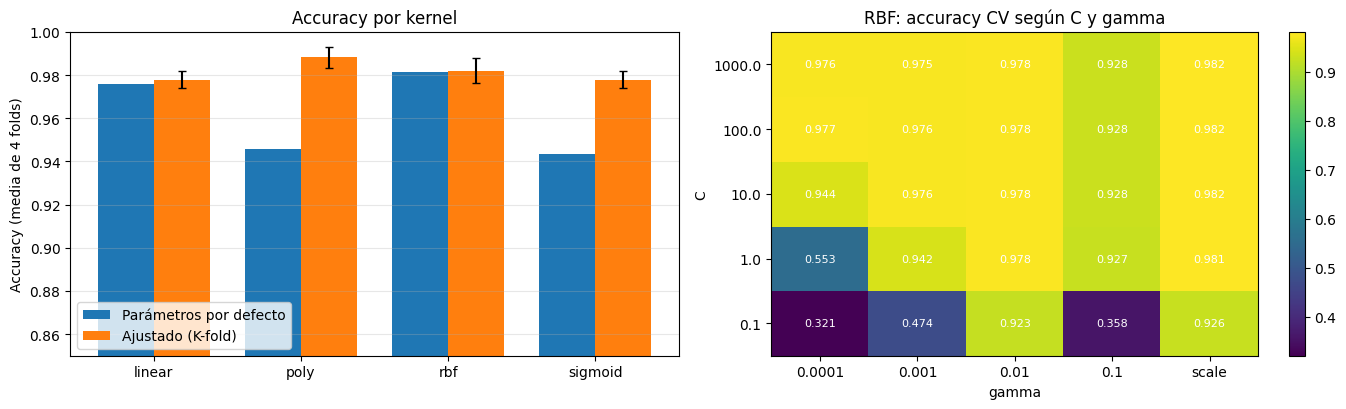

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))

# Accuracy por kernel: defecto vs ajustado
idx = np.arange(4); w = 0.38
axes[0].bar(idx - w/2, base["Accuracy"], w, label="Parámetros por defecto")
axes[0].bar(idx + w/2, tuned["Accuracy"], w, yerr=tuned["± Acc"], capsize=3, label="Ajustado (K-fold)")
axes[0].set_xticks(idx); axes[0].set_xticklabels(base.index)
axes[0].set_ylim(0.85, 1.0); axes[0].set_ylabel("Accuracy (media de 4 folds)")
axes[0].set_title("Accuracy por kernel"); axes[0].legend(); axes[0].grid(alpha=.3, axis="y")

# Mapa de calor C vs gamma para RBF
r = pd.DataFrame(busquedas["rbf"].cv_results_)
r["gamma"] = r["param_svc__gamma"].astype(str); r["C"] = r["param_svc__C"]
tabla = r.pivot(index="C", columns="gamma", values="mean_test_accuracy")
orden = ["0.0001", "0.001", "0.01", "0.1", "scale"]
tabla = tabla[[c for c in orden if c in tabla.columns]]
im = axes[1].imshow(tabla.values, cmap="viridis", aspect="auto", origin="lower")
axes[1].set_xticks(range(tabla.shape[1])); axes[1].set_xticklabels(tabla.columns)
axes[1].set_yticks(range(tabla.shape[0])); axes[1].set_yticklabels(tabla.index)
for (i, j), v in np.ndenumerate(tabla.values):
    axes[1].text(j, i, f"{v:.3f}", ha="center", va="center", color="w", fontsize=8)
axes[1].set_xlabel("gamma"); axes[1].set_ylabel("C"); axes[1].set_title("RBF: accuracy CV según C y gamma")
plt.colorbar(im, ax=axes[1]); plt.tight_layout(); plt.show()

## 4. Selección del kernel
Se elige el kernel con **mayor accuracy promedio en K-fold**. Si dos kernels quedan a menos de una desviación estándar, se prefiere el más simple o el más rápido, porque la diferencia no es significativa. La prueba **no** interviene en la elección.

In [5]:
mejor_kernel = tuned["Accuracy"].idxmax()
print("Ranking por accuracy en K-fold:")
print(tuned["Accuracy"].sort_values(ascending=False).round(4).to_string())
print("\nKernel seleccionado:", mejor_kernel)
print("Parámetros:", tuned.loc[mejor_kernel, "Mejores parámetros"])

Ranking por accuracy en K-fold:
Kernel
poly       0.9882
rbf        0.9819
linear     0.9777
sigmoid    0.9777

Kernel seleccionado: poly
Parámetros: {'C': 0.1, 'coef0': 1, 'degree': 4, 'gamma': 'scale'}


## 5. Evaluación final en prueba
El modelo seleccionado ya fue reajustado con todo el entrenamiento por `GridSearchCV` (`refit`). Se evalúa **una sola vez** en el 20 % reservado.

SVM kernel=poly — Accuracy en prueba: 0.9889

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        36
           1     0.9459    0.9722    0.9589        36
           2     1.0000    1.0000    1.0000        35
           3     1.0000    1.0000    1.0000        37
           4     1.0000    1.0000    1.0000        36
           5     0.9737    1.0000    0.9867        37
           6     1.0000    1.0000    1.0000        36
           7     0.9730    1.0000    0.9863        36
           8     1.0000    0.9429    0.9706        35
           9     1.0000    0.9722    0.9859        36

    accuracy                         0.9889       360
   macro avg     0.9893    0.9887    0.9888       360
weighted avg     0.9892    0.9889    0.9889       360



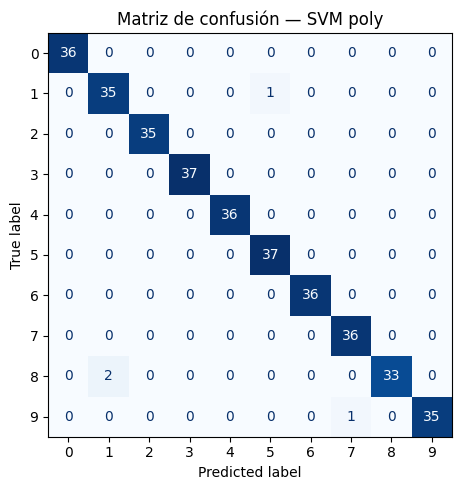

Errores: 4 de 360


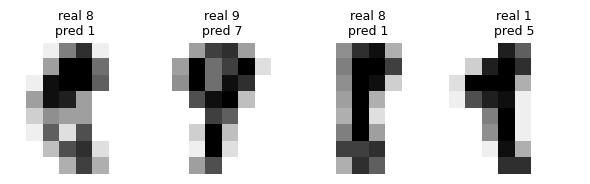

In [6]:
modelo_svm = busquedas[mejor_kernel].best_estimator_
y_pred_svm = modelo_svm.predict(X_test)

print(f"SVM kernel={mejor_kernel} — Accuracy en prueba: {accuracy_score(y_test, y_pred_svm):.4f}\n")
print(classification_report(y_test, y_pred_svm, digits=4))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_svm, cmap="Blues", colorbar=False, ax=ax)
ax.set_title(f"Matriz de confusión — SVM {mejor_kernel}"); plt.tight_layout(); plt.show()

errores = np.flatnonzero(y_pred_svm != y_test)
print(f"Errores: {len(errores)} de {len(y_test)}")
if len(errores):
    n = min(10, len(errores))
    fig, axes = plt.subplots(1, n, figsize=(1.5 * n, 2.2), squeeze=False)
    for ax, i in zip(axes[0], errores[:n]):
        ax.imshow(X_test[i].reshape(8, 8), cmap="gray_r")
        ax.set_title(f"real {y_test[i]}\npred {y_pred_svm[i]}", fontsize=9); ax.axis("off")
    plt.tight_layout(); plt.show()

## 6. Comparación con los Talleres 9 y 10
Para comparar de forma justa, se **reentrenan aquí los mejores modelos de los talleres anteriores con la misma partición 80/20 y los mismos 4 folds**:

- **Taller 9 (Bayesianos):** `GaussianNB(var_smoothing=0.1)`, el mejor por K-fold en ese taller.
- **Taller 10 (MLP):** una capa oculta de 50 neuronas, activación `tanh`, solver L-BFGS, con `StandardScaler`.

Nota: en el Taller 10 se usó una partición distinta (60/20/20), por lo que sus cifras originales no son directamente comparables con las de los otros dos; por eso se vuelve a evaluar aquí con la partición común.

                        Acc CV    ± CV   F1 CV  Acc prueba  Prec. prueba  Rec. prueba  F1 prueba  Entrenar (s)  Predecir (s)
Modelo                                                                                                                      
Taller 9 — GaussianNB   0.9248  0.0076  0.9250      0.9222        0.9224       0.9220     0.9211        0.0023        0.0013
Taller 10 — MLP (tanh)  0.9680  0.0031  0.9677      0.9778        0.9779       0.9776     0.9775        0.3625        0.0040
Taller 11 — SVM (poly)  0.9882  0.0050  0.9881      0.9889        0.9893       0.9887     0.9888        0.0448        0.0119


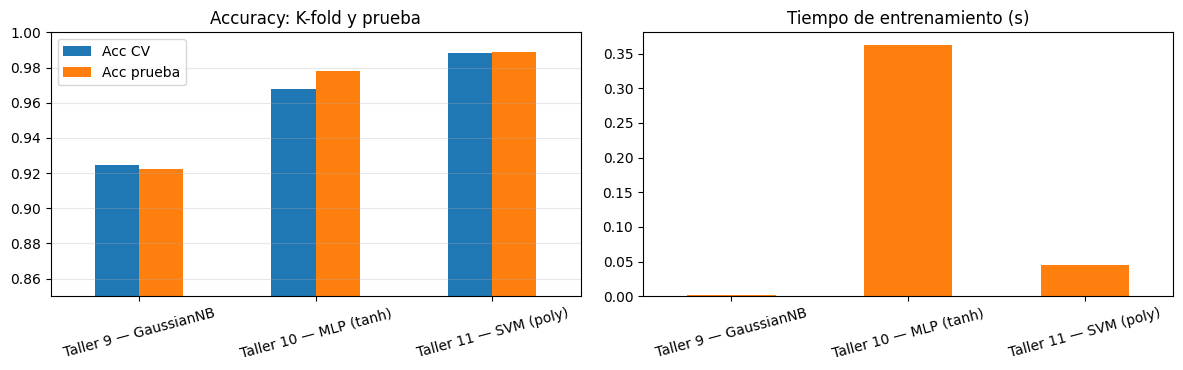

In [7]:
rivales = {
    "Taller 9 — GaussianNB": GaussianNB(var_smoothing=0.1),
    "Taller 10 — MLP (tanh)": Pipeline([("escala", StandardScaler()),
        ("mlp", MLPClassifier(hidden_layer_sizes=(50,), activation="tanh", solver="lbfgs",
                              alpha=1e-4, tol=1e-6, max_iter=2000, random_state=SEMILLA))]),
    f"Taller 11 — SVM ({mejor_kernel})": modelo_svm,
}

filas = []
for nombre, modelo in rivales.items():
    # K-fold (mismos folds para todos)
    r = cross_validate(modelo, X_train, y_train, cv=cv, scoring=METRICAS)
    # Tiempo de entrenamiento completo y prueba
    t0 = time.perf_counter(); modelo.fit(X_train, y_train); seg = time.perf_counter() - t0
    t0 = time.perf_counter(); p = modelo.predict(X_test); seg_pred = time.perf_counter() - t0
    filas.append({"Modelo": nombre,
                  "Acc CV": r["test_accuracy"].mean(), "± CV": r["test_accuracy"].std(),
                  "F1 CV": r["test_f1"].mean(),
                  "Acc prueba": accuracy_score(y_test, p),
                  "Prec. prueba": precision_score(y_test, p, average="macro"),
                  "Rec. prueba": recall_score(y_test, p, average="macro"),
                  "F1 prueba": f1_score(y_test, p, average="macro"),
                  "Entrenar (s)": seg, "Predecir (s)": seg_pred})
comparacion = pd.DataFrame(filas).set_index("Modelo")
print(comparacion.round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
comparacion[["Acc CV", "Acc prueba"]].plot.bar(ax=axes[0], rot=15)
axes[0].set_ylim(0.85, 1.0); axes[0].set_title("Accuracy: K-fold y prueba"); axes[0].grid(alpha=.3, axis="y")
comparacion["Entrenar (s)"].plot.bar(ax=axes[1], rot=15, color="tab:orange")
axes[1].set_title("Tiempo de entrenamiento (s)")
for ax in axes: ax.set_xlabel("")
plt.tight_layout(); plt.show()

## 7. Análisis y conclusiones

### Mejor kernel
Con los parámetros por defecto, el mejor kernel fue `rbf` (98,1 % de accuracy) y los peores fueron `poly` y `sigmoid` (≈ 94,5 %). Pero esa comparación no era justa, porque a cada kernel le faltaba ajustar sus hiperparámetros. Después de ajustarlos con `GridSearchCV`, el resultado cambia:

| Kernel | Accuracy (K-fold = 4) | Mejores parámetros |
| --- | ---: | --- |
| **poly** | **0,988** | C=0,1, grado 4, coef0=1 |
| rbf | 0,982 | C=10, gamma='scale' |
| linear | 0,978 | C=0,1 |
| sigmoid | 0,978 | C=100, gamma=0,001 |

El kernel **polinómico** fue el mejor. En el conjunto de prueba obtuvo ≈ **98,9 %** de accuracy (solo 4 errores de 360), un resultado parecido al de K-fold.

Hay que tener en cuenta dos cosas:
- La ventaja de `poly` sobre `rbf` es muy pequeña (≈ 0,6 puntos), tan pequeña como la variación normal entre folds. Además, los parámetros se eligieron con los mismos folds, así que la cifra de K-fold puede ser un poco optimista.
- Los **cuatro kernels, bien ajustados, superan el 97 %**. Los dígitos son casi separables con una línea recta, por eso hasta el kernel lineal queda muy cerca. Ajustar `C` y `gamma` importó más que escoger el tipo de kernel: `sigmoid` subió de 94,4 % a 97,8 % solo con ajustarlo.

### Errores
Los dígitos con peor resultado fueron el **1** (precisión 0,946) y el **8** (recall 0,943). Es normal, porque con imágenes de solo 8×8 píxeles estos dígitos se parecen a otros.

### Comparación con los Talleres 9 y 10
Se usó la misma partición 80/20 y los mismos 4 folds para los tres modelos:

| Modelo | Accuracy K-fold | Accuracy prueba | F1 macro prueba | Entrenar (s) |
| --- | ---: | ---: | ---: | ---: |
| Taller 9: GaussianNB | 0,925 | 0,922 | 0,921 | ≈ 0,002 |
| Taller 10: MLP (tanh) | 0,968 | 0,978 | 0,978 | ≈ 0,04 |
| **Taller 11: SVM (poly)** | **0,988** | **0,989** | **0,989** | ≈ 0,03 |

- **Orden de resultados: SVM > MLP > Naive Bayes.** Naive Bayes supone que cada píxel es independiente de los demás, pero en una imagen los píxeles vecinos están muy relacionados. Por eso queda ≈ 6 puntos por debajo. Su ventaja es que entrena casi al instante.
- **SVM frente a MLP:** la SVM es mejor por ≈ 2 puntos en K-fold y ≈ 1 punto en prueba, con un tiempo de entrenamiento parecido. En prueba son solo unas 4 imágenes de 360, así que es una ventaja pequeña, aunque se repite en K-fold y en prueba. Además, el MLP depende de la inicialización aleatoria y tiene más cosas que ajustar (arquitectura y activación), mientras que la SVM da siempre el mismo resultado para un `C` y un kernel dados.
- **Nota sobre el Taller 10:** allí el MLP obtuvo ≈ 96,4 % en prueba con la partición 60/20/20. Aquí el mismo modelo obtiene ≈ 97,8 % porque se entrena con el 80 % de los datos. La diferencia viene de la partición, no del modelo.

### Conclusión
Para clasificar `digits`, la SVM con kernel polinómico fue el mejor de los tres talleres y entrena rápido. Si solo importara la velocidad, Naive Bayes sería la opción, pero perdiendo unos 6 puntos de accuracy.

### Limitaciones
- Las mallas de hiperparámetros son pequeñas.
- Los mismos folds se usaron para ajustar y para comparar.
- Los tiempos son de décimas de segundo y cambian según la máquina.
- Para asegurar que un modelo es mejor que otro, habría que repetir el experimento con varias particiones o usar validación cruzada anidada.